### PyTorch und Bildklassifikation

[In Google Colab öffnen](https://colab.research.google.com/github/ktheu/InfoKursN/blob/main/neuronaleNetze4/inhalte/pytorch.ipynb)

In den Notebooks Perzeptron und Neuron, Gradientenabstieg und Backpropagation haben wir alles selbst programmiert.
Für große Netze benutzt man eine Bibliothek. Die verbreitetste ist **PyTorch**. Sie rechnet mit **Tensoren**,
berechnet die Ableitungen automatisch (wie unsere Klasse `Wert`) und kann die Rechnungen auf einer Grafikkarte (GPU)
ausführen.

In diesem Notebook

1. lernen wir Tensoren kennen,
2. prüfen wir, dass PyTorch dieselben Ableitungen liefert wie unsere Rechnung von Hand,
3. trainieren wir ein Netz, das Bilder von Kleidungsstücken erkennt.

#### Das Notebook in Google Colab ausführen

PyTorch braucht viel Speicher und Rechenleistung und läuft nicht im Browser wie JupyterLite. Am einfachsten ist
**Google Colab**: ein Jupyter-Notebook in der Cloud, in dem PyTorch schon installiert ist. Man braucht dafür ein
Google-Konto.

- Den Link oben anklicken. Das Notebook öffnet sich in Colab.
- Eine Zelle startet man mit Umschalt + Enter oder mit dem Dreieck links neben der Zelle.
- Zum Speichern eigener Änderungen: *Datei → Kopie in Drive speichern*.
- Optional eine GPU einschalten: *Laufzeit → Laufzeittyp ändern → T4-GPU*. Das Notebook läuft aber auch ohne GPU,
  das Training dauert dann etwas länger.

Wer das Notebook auf dem eigenen Rechner ausführen will, installiert vorher PyTorch mit
`pip install torch torchvision`.

In [1]:
import torch

print('PyTorch', torch.__version__)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Gerät:', device)

PyTorch 2.14.1+cpu
Gerät: cpu


`device` ist `'cuda'`, wenn eine GPU zur Verfügung steht, sonst `'cpu'`. Wir benutzen die Variable später beim
Training. Die Ausgaben in diesem Notebook wurden ohne GPU erzeugt. In Colab können Zeiten und Zahlen etwas
abweichen.

### Tensoren

Ein **Tensor** ist eine Verallgemeinerung von Liste und Matrix. Ein Tensor mit **Dimension** 1 ist ein Vektor, auf
seine Elemente greift man mit einem Index zu. Mit Dimension 2 ist er eine Matrix (zwei Indizes), mit Dimension 3 ein
Quader aus hintereinander gestapelten Matrizen (drei Indizes) und so weiter. `shape` gibt an, wie viele Elemente es
in jeder Dimension gibt.

In [2]:
t1 = torch.tensor([1, 2, 3])
t2 = torch.tensor([[1, 2, 3], [4, 5, 6]])
t3 = torch.tensor([[[1, 2, 3], [4, 5, 6]], [[7, 8, 9], [10, 11, 12]]])

for t in [t1, t2, t3]:
    print(t.dim(), t.shape)
print(t2[1][2].item(), t3[1][1][1].item())

1 torch.Size([3])
2 torch.Size([2, 3])
3 torch.Size([2, 2, 3])
6 11


`t2[1][2]` ist die Zeile 1, Spalte 2 der Matrix, also 6. `t3[1][1][1]` ist in der zweiten Matrix die Zeile 1,
Spalte 1, also 11. Mit `.item()` bekommt man aus einem Tensor mit einem Element die Zahl.

Ein Farbbild ist z.B. ein Tensor mit Dimension 3: Farbkanal (rot, grün, blau), Zeile, Spalte. Viele Bilder auf
einmal ergeben einen Tensor mit Dimension 4.

#### Reshape

`reshape` ordnet dieselben Elemente in eine andere Gestalt um. Die Reihenfolge der Elemente bleibt dabei gleich,
gefüllt wird zeilenweise.

In [3]:
t = torch.arange(120)
print(t.shape)
print(t.reshape(2, 60).shape, t.reshape(2, 3, 20).shape, t.reshape(2, 3, 4, 5).shape)
print(t.reshape(2, 3, 20)[1][2][17].item())
print(t.reshape(10, -1).shape)

torch.Size([120])
torch.Size([2, 60]) torch.Size([2, 3, 20]) torch.Size([2, 3, 4, 5])
117
torch.Size([10, 12])


In `t.reshape(2, 3, 20)` hat jede der 2 Matrizen 60 Elemente, jede ihrer 3 Zeilen 20. Das Element `[1][2][17]` steht
deshalb an der Stelle $1 \cdot 60 + 2 \cdot 20 + 17 = 117$. Eine `-1` bei `reshape` bedeutet: Diese Größe soll
PyTorch selbst ausrechnen, hier $120 / 10 = 12$.

#### Rechnen mit Tensoren

Rechenzeichen wirken **elementweise**, `@` ist das **Matrixprodukt**:

In [4]:
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([10.0, 20.0, 30.0])
print(a + b, a * b, 2 * a)

M = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
v = torch.tensor([1.0, -1.0])
print(M @ v)

tensor([11., 22., 33.]) tensor([10., 40., 90.]) tensor([2., 4., 6.])
tensor([-1., -1.])


Beim Matrixprodukt `M @ v` wird jede Zeile von `M` mit `v` multipliziert und aufsummiert: $1 \cdot 1 + 2 \cdot (-1)
= -1$ und $3 \cdot 1 + 4 \cdot (-1) = -1$.

Damit kann ein Neuron alle vier Inputs von OR auf einmal verarbeiten. Jede Zeile von `X` ist ein Input, das
Matrixprodukt bildet für jede Zeile die gewichtete Summe:

In [5]:
X = torch.tensor([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
w = torch.tensor([4.0, 4.0])
bias = -2.0

z = X @ w + bias
print(z)
print(torch.sigmoid(z))

tensor([-2.,  2.,  2.,  6.])
tensor([0.1192, 0.8808, 0.8808, 0.9975])


Statt einer Schleife über die Beispiele steht hier eine einzige Rechnung. Das nennt man **Vektorisierung**. Eine GPU
kann tausende solcher Multiplikationen gleichzeitig ausführen. Grafikkarten wurden dafür gebaut, Bilder für Spiele
zu berechnen, z.B. Drehungen vieler Punkte mit einer Matrix. Dieselbe Rechenart braucht man für neuronale Netze.

### Automatische Ableitungen

Setzt man bei einem Tensor `requires_grad=True`, merkt sich PyTorch jede Rechnung damit, also den Rechengraphen.
`backward()` geht ihn rückwärts durch und speichert die Ableitungen in `.grad`, genau wie unsere Klasse `Wert` aus
Backpropagation. Das erste Beispiel von dort, $f = (x + y) \cdot z$ mit $x = 1$, $y = 2$, $z = -2$:

In [6]:
x = torch.tensor(1.0, requires_grad=True)
y = torch.tensor(2.0, requires_grad=True)
z = torch.tensor(-2.0, requires_grad=True)

f = (x + y) * z
f.backward()
print(f.item(), x.grad.item(), y.grad.item(), z.grad.item())

-6.0 -2.0 -2.0 3.0


Wie im Rechengraphen: $\frac{\partial f}{\partial x} = \frac{\partial f}{\partial y} = -2$ und
$\frac{\partial f}{\partial z} = 3$.

Jetzt das Netz aus Stufe 4 in Backpropagation: zwei Inputs $x = (1, 1)$, zwei versteckte Neuronen mit ReLU, eine
Ausgabe mit Sigmoid, $y = 1$. Gewichte und Biaswerte sind die aus der Tabelle dort. `binary_cross_entropy` berechnet
den Fehler.

In [7]:
import torch.nn.functional as F

x = torch.tensor([1.0, 1.0])
y = torch.tensor([1.0])
W = torch.tensor([[1.0, 0.5], [0.5, 0.5]], requires_grad=True)
b = torch.tensor([-0.5, 1.0], requires_grad=True)
V = torch.tensor([[2.0, -1.0]], requires_grad=True)
c = torch.tensor([0.0], requires_grad=True)

h = torch.relu(W @ x + b)
yh = torch.sigmoid(V @ h + c)
L = F.binary_cross_entropy(yh, y)
L.backward()

print('h =', h, ' yh =', yh.item(), ' L =', round(L.item(), 4))
print('dL/dW =', W.grad)
print('dL/db =', b.grad)
print('dL/dV =', V.grad, ' dL/dc =', c.grad)

h = tensor([1., 2.], grad_fn=<ReluBackward0>)  yh = 0.5  L = 0.6931
dL/dW = tensor([[-1.0000, -1.0000],
        [ 0.5000,  0.5000]])
dL/db = tensor([-1.0000,  0.5000])
dL/dV = tensor([[-0.5000, -1.0000]])  dL/dc = tensor([-0.5000])


Das sind genau die Werte, die wir in Backpropagation von Hand berechnet haben:
$\frac{\partial L}{\partial w_{11}} = \frac{\partial L}{\partial w_{12}} = \frac{\partial L}{\partial b_1} = -1$,
$\frac{\partial L}{\partial w_{21}} = \frac{\partial L}{\partial w_{22}} = \frac{\partial L}{\partial b_2} = 0.5$,
$\frac{\partial L}{\partial v_1} = -0.5$, $\frac{\partial L}{\partial v_2} = -1$ und
$\frac{\partial L}{\partial c} = -0.5$.

Ruft man `backward()` noch einmal auf, werden die neuen Ableitungen zu den alten **addiert** (wie das `+=` in der
Klasse `Wert`). Vor jedem Trainingsschritt muss man die Ableitungen deshalb auf 0 setzen.

### Ein Netz mit `nn.Module`

Bei großen Netzen legt man die Gewichte nicht von Hand an. PyTorch bietet fertige Bausteine. `nn.Linear(2, 2)` ist
eine Schicht mit 2 Inputs und 2 Neuronen: Sie enthält eine Gewichtsmatrix mit $2 \cdot 2$ Gewichten und 2 Biaswerte
und berechnet $W x + b$. Ein Netz ist eine Klasse, die von `nn.Module` erbt. In `__init__` legt man die Schichten an,
in `forward` steht der Weg vom Input zur Ausgabe.

In [8]:
import torch.nn as nn

class Netz221(nn.Module):
    def __init__(self):
        super().__init__()
        self.schicht1 = nn.Linear(2, 2)
        self.schicht2 = nn.Linear(2, 1)

    def forward(self, x):
        x = torch.relu(self.schicht1(x))
        x = torch.sigmoid(self.schicht2(x))
        return x

netz = Netz221()
for name, p in netz.named_parameters():
    print(name, p.shape)

schicht1.weight torch.Size([2, 2])
schicht1.bias torch.Size([2])
schicht2.weight torch.Size([1, 2])
schicht2.bias torch.Size([1])


Am Anfang sind die Gewichte zufällig. Wir setzen sie auf die Werte aus Stufe 4 und machen einen Schritt des
Gradientenabstiegs mit $lr = 0.1$. Den Schritt führt ein **Optimizer** aus. `SGD` (stochastic gradient descent)
rechnet genau $p_{neu} = p - lr \cdot \frac{\partial L}{\partial p}$.

In [9]:
with torch.no_grad():
    netz.schicht1.weight[:] = torch.tensor([[1.0, 0.5], [0.5, 0.5]])
    netz.schicht1.bias[:] = torch.tensor([-0.5, 1.0])
    netz.schicht2.weight[:] = torch.tensor([[2.0, -1.0]])
    netz.schicht2.bias[:] = torch.tensor([0.0])

optimizer = torch.optim.SGD(netz.parameters(), lr=0.1)
x = torch.tensor([[1.0, 1.0]])
y = torch.tensor([[1.0]])

loss = F.binary_cross_entropy(netz(x), y)
optimizer.zero_grad()
loss.backward()
optimizer.step()

print(netz.schicht1.weight.data, netz.schicht1.bias.data)
print(netz.schicht2.weight.data, netz.schicht2.bias.data)
print('Fehler vorher:', round(loss.item(), 4), ' nachher:', round(F.binary_cross_entropy(netz(x), y).item(), 4))

tensor([[1.1000, 0.6000],
        [0.4500, 0.4500]]) tensor([-0.4000,  0.9500])
tensor([[ 2.0500, -0.9000]]) tensor([0.0500])
Fehler vorher: 0.6931  nachher: 0.3001


Die neuen Parameter und der neue Fehler 0.3001 sind dieselben wie in Backpropagation. `torch.no_grad()` sorgt dafür,
dass das Setzen der Gewichte nicht in den Rechengraphen aufgenommen wird.

Ein Trainingsschritt besteht in PyTorch immer aus denselben vier Zeilen:

| Zeile | Bedeutung |
|---|---|
| `loss = F.binary_cross_entropy(netz(x), y)` | vorwärts rechnen, Fehler bestimmen |
| `optimizer.zero_grad()` | alte Ableitungen auf 0 setzen |
| `loss.backward()` | Backpropagation: alle Ableitungen berechnen |
| `optimizer.step()` | alle Parameter gegen ihre Ableitung verschieben |

#### XOR mit PyTorch

Dasselbe Netz wie in Backpropagation, mit 8 versteckten Neuronen. Alle vier Beispiele stehen in einem Tensor, PyTorch
verarbeitet sie in einem Schritt und mittelt den Fehler.

In [10]:
class NetzXOR(nn.Module):
    def __init__(self):
        super().__init__()
        self.schicht1 = nn.Linear(2, 8)
        self.schicht2 = nn.Linear(8, 1)

    def forward(self, x):
        return torch.sigmoid(self.schicht2(torch.relu(self.schicht1(x))))

torch.manual_seed(1)
X = torch.tensor([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
Y = torch.tensor([[0.0], [1.0], [1.0], [0.0]])

netz = NetzXOR()
optimizer = torch.optim.SGD(netz.parameters(), lr=0.5)
for epoche in range(2000):
    loss = F.binary_cross_entropy(netz(X), Y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print('Fehler:', round(loss.item(), 4))
print(netz(X).detach().round(decimals=4))

Fehler: 0.0006
tensor([[1.1000e-03],
        [9.9950e-01],
        [9.9950e-01],
        [4.0000e-04]])


`torch.manual_seed(1)` legt die Zufallszahlen für die Startgewichte fest, damit das Ergebnis jedes Mal gleich ist.
`.detach()` löst das Ergebnis vom Rechengraphen, damit man es ausgeben kann.

### Bildklassifikation: Fashion-MNIST

Jetzt eine echte Aufgabe. Der Datensatz [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) von Zalando
enthält 70000 Graustufenbilder von Kleidungsstücken, jedes $28 \times 28$ Pixel groß, mit einer von 10 Klassen. Er
wird beim ersten Aufruf heruntergeladen (etwa 30 MB) und in den Ordner `data` gespeichert.

In [11]:
import contextlib
import io
import torchvision
import torchvision.transforms as transforms

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    train_set = torchvision.datasets.FashionMNIST('data', train=True, download=True, transform=transforms.ToTensor())
    test_set = torchvision.datasets.FashionMNIST('data', train=False, download=True, transform=transforms.ToTensor())

klassen = ['T-Shirt', 'Hose', 'Pullover', 'Kleid', 'Mantel', 'Sandale', 'Hemd', 'Sneaker', 'Tasche', 'Stiefel']
print(len(train_set), len(test_set))
print(train_set.targets.bincount())

60000 10000
tensor([6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000])


60000 Bilder sind zum Trainieren da, 10000 zum Testen. Jede Klasse kommt 6000-mal vor. Die `with`-Zeile unterdrückt
nur die Fortschrittsanzeige beim Herunterladen.

Ein Bild ist ein Tensor mit der Gestalt (Kanal, Zeile, Spalte). Bei Graustufenbildern gibt es nur einen Kanal.
`ToTensor()` wandelt die Grauwerte 0 bis 255 in Zahlen von 0 bis 1 um.

In [12]:
bild, label = train_set[0]
print(bild.shape, label, klassen[label])
print(bild.min().item(), bild.max().item())

torch.Size([1, 28, 28]) 9 Stiefel
0.0 1.0


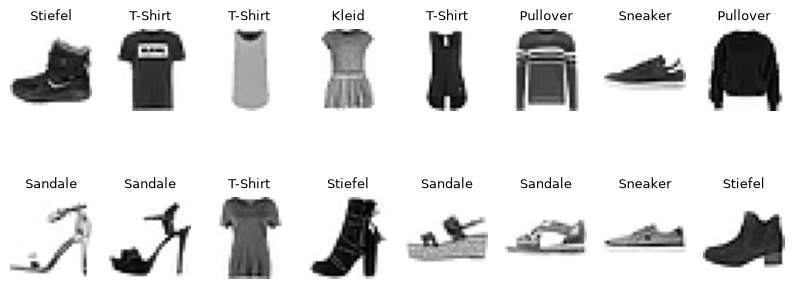

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
for i in range(16):
    bild, label = train_set[i]
    plt.subplot(2, 8, i + 1)
    plt.imshow(bild[0], cmap='gray_r')
    plt.title(klassen[label], fontsize=9)
    plt.axis('off')
plt.show()

Beim Training gibt man dem Netz nicht jedes Bild einzeln, sondern **Batches** von z.B. 100 Bildern. Für jeden Batch
gibt es einen Schritt des Gradientenabstiegs mit dem mittleren Fehler des Batches. Einen Batch liefert ein
`DataLoader`. `shuffle=True` mischt die Trainingsbilder in jeder Epoche neu.

In [14]:
torch.manual_seed(0)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=100, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1000)

bilder, labels = next(iter(train_loader))
print(bilder.shape, labels.shape)
print(labels[:10])

torch.Size([100, 1, 28, 28]) torch.Size([100])
tensor([3, 9, 5, 0, 9, 0, 3, 8, 3, 1])


Ein Batch hat die Gestalt (100, 1, 28, 28): 100 Bilder mit je einem Kanal und $28 \times 28$ Pixeln. Eine Epoche
besteht aus $60000 / 100 = 600$ Schritten.

### Mehr als zwei Klassen: Softmax und Cross-Entropy

Bisher hatte das Netz eine Ausgabe, die Wahrscheinlichkeit für Klasse 1. Bei 10 Klassen hat das letzte Layer 10
Neuronen, für jede Klasse eines. Ihre Werte heißen **Logits**, sie können beliebige reelle Zahlen sein. Die
**Softmax-Funktion** macht daraus Wahrscheinlichkeiten:

$$p_k = \frac{e^{z_k}}{e^{z_1} + e^{z_2} + \dots + e^{z_n}}$$

Die e-Funktion macht alle Werte positiv, das Teilen durch die Summe sorgt dafür, dass sie zusammen 1 ergeben. Der
größte Logit bekommt die größte Wahrscheinlichkeit. Beispiel mit drei Klassen:

In [15]:
import math

logits = torch.tensor([2.0, -1.0, 0.1])
print([round(math.exp(z), 4) for z in logits.tolist()])
print(torch.softmax(logits, dim=0))

[7.3891, 0.3679, 1.1052]
tensor([0.8338, 0.0415, 0.1247])


$e^2 = 7.3891$, $e^{-1} = 0.3679$, $e^{0.1} = 1.1052$, die Summe ist 8.8622. Daraus folgen die Wahrscheinlichkeiten
$7.3891 / 8.8622 = 0.8338$, $0.0415$ und $0.1247$.

Der Fehler ist wie bei Binary Cross-Entropy der **negative Logarithmus der Wahrscheinlichkeit, die das Netz der
richtigen Klasse gibt**. Das heißt **Cross-Entropy**. Ist die richtige Klasse hier die Nummer 2, ist der Fehler
$-\ln(0.1247) = 2.0818$:

In [16]:
print(-math.log(torch.softmax(logits, dim=0)[2].item()))
print(F.cross_entropy(logits.reshape(1, 3), torch.tensor([2])).item())

2.08178442204043
2.08178448677063


`F.cross_entropy` bekommt die Logits und die Nummer der richtigen Klasse und wendet die Softmax-Funktion selbst an.
Deshalb hat das letzte Layer unseres Netzes **keine** Aktivierungsfunktion.

### Das Netz

Das Netz bekommt die $28 \cdot 28 = 784$ Pixel als Input. `reshape(-1, 784)` macht aus jedem Bild einen Vektor, die
`-1` steht für die Anzahl der Bilder im Batch. Es folgen zwei versteckte Schichten mit 120 und 60 Neuronen (ReLU) und
die Ausgabeschicht mit 10 Neuronen.

In [17]:
class NetzFashion(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 120)
        self.fc2 = nn.Linear(120, 60)
        self.fc3 = nn.Linear(60, 10)

    def forward(self, t):
        t = t.reshape(-1, 784)
        t = torch.relu(self.fc1(t))
        t = torch.relu(self.fc2(t))
        return self.fc3(t)

netz = NetzFashion()
for name, p in netz.named_parameters():
    print(name, p.shape, p.numel())
print('Parameter insgesamt:', sum(p.numel() for p in netz.parameters()))
print(netz(bilder).shape)

fc1.weight torch.Size([120, 784]) 94080
fc1.bias torch.Size([120]) 120
fc2.weight torch.Size([60, 120]) 7200
fc2.bias torch.Size([60]) 60
fc3.weight torch.Size([10, 60]) 600
fc3.bias torch.Size([10]) 10
Parameter insgesamt: 102070
torch.Size([100, 10])


Die erste Schicht hat $784 \cdot 120 = 94080$ Gewichte und 120 Biaswerte, die zweite $120 \cdot 60 + 60 = 7260$, die
dritte $60 \cdot 10 + 10 = 610$. Zusammen sind das 102070 Parameter. Für einen Batch von 100 Bildern liefert das Netz
100 mal 10 Logits.

### Training

Die Funktion `trainiere` macht eine Epoche: 600 Schritte mit je einem Batch. `genauigkeit` zählt, wie viele Bilder
richtig erkannt werden. Die vorhergesagte Klasse ist die mit dem größten Logit, `argmax`. Die Bilder werden mit
`.to(device)` auf die GPU geschoben, wenn es eine gibt.

Als Optimizer nehmen wir **Adam** statt SGD (mehr dazu unten).

In [18]:
import time

def trainiere(netz, loader, optimizer):
    netz.train()
    summe = 0
    for bilder, labels in loader:
        bilder, labels = bilder.to(device), labels.to(device)
        loss = F.cross_entropy(netz(bilder), labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        summe += loss.item()
    return summe / len(loader)

def genauigkeit(netz, loader):
    netz.eval()
    richtig = 0
    with torch.no_grad():
        for bilder, labels in loader:
            bilder, labels = bilder.to(device), labels.to(device)
            richtig += (netz(bilder).argmax(dim=1) == labels).sum().item()
    return richtig / len(loader.dataset)

torch.manual_seed(0)
netz = NetzFashion().to(device)
optimizer = torch.optim.Adam(netz.parameters(), lr=0.001)

verlauf = []
for epoche in range(5):
    start = time.time()
    fehler = trainiere(netz, train_loader, optimizer)
    train_gen = genauigkeit(netz, train_loader)
    test_gen = genauigkeit(netz, test_loader)
    verlauf.append((fehler, train_gen, test_gen))
    print(f'Epoche {epoche + 1}: Fehler {fehler:.4f}  Training {train_gen:.4f}  Test {test_gen:.4f}  ({time.time() - start:.0f} s)')

Epoche 1: Fehler 0.5942  Training 0.8520  Test 0.8374  (18 s)


Epoche 2: Fehler 0.4080  Training 0.8680  Test 0.8532  (18 s)


Epoche 3: Fehler 0.3658  Training 0.8769  Test 0.8575  (18 s)


Epoche 4: Fehler 0.3415  Training 0.8847  Test 0.8673  (18 s)


Epoche 5: Fehler 0.3211  Training 0.8785  Test 0.8560  (18 s)


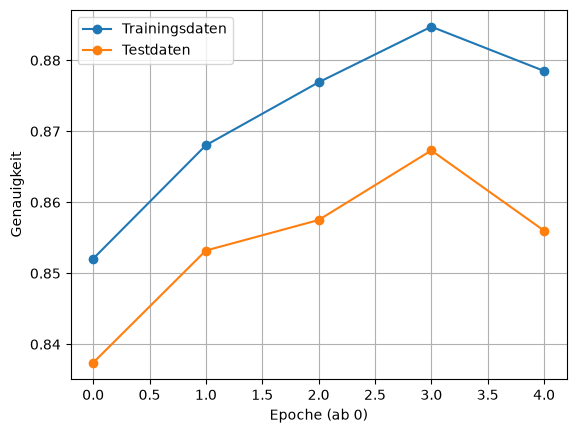

In [19]:
plt.plot([v[1] for v in verlauf], 'o-', label='Trainingsdaten')
plt.plot([v[2] for v in verlauf], 'o-', label='Testdaten')
plt.xlabel('Epoche (ab 0)')
plt.ylabel('Genauigkeit')
plt.legend()
plt.grid()
plt.show()

Schon nach der ersten Epoche erkennt das Netz mehr als 80 Prozent der Testbilder, nach vier Epochen fast 87 Prozent.
In der fünften Epoche sinkt der Wert wieder etwas, solche Schwankungen sind normal.
Raten würde 10 Prozent ergeben. Auf den Trainingsbildern ist es etwas besser als auf den Testbildern, die es nie
gesehen hat.

#### Was das Netz falsch macht

Für jede Klasse zählen wir, wie viele Testbilder richtig erkannt werden:

In [20]:
netz.eval()
alle_vorhersagen = []
with torch.no_grad():
    for bilder, labels in test_loader:
        alle_vorhersagen.append(netz(bilder.to(device)).argmax(dim=1).cpu())
vorhersagen = torch.cat(alle_vorhersagen)
labels = test_set.targets

for k in range(10):
    auswahl = labels == k
    print(f'{klassen[k]:10} {(vorhersagen[auswahl] == k).float().mean().item():.3f}')

T-Shirt    0.704
Hose       0.964
Pullover   0.720
Kleid      0.889
Mantel     0.859
Sandale    0.983
Hemd       0.639
Sneaker    0.910
Tasche     0.959
Stiefel    0.933


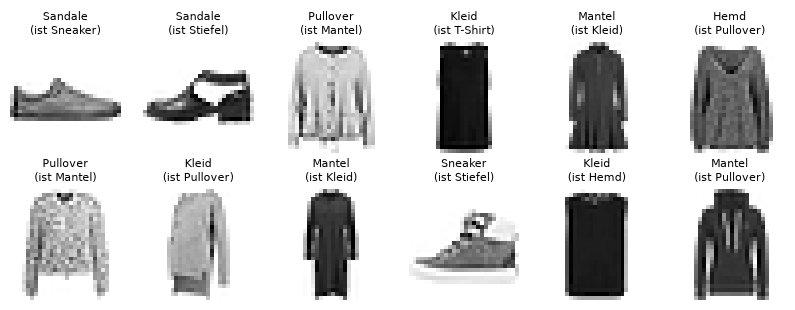

In [21]:
falsch = (vorhersagen != labels).nonzero().flatten()[:12]
plt.figure(figsize=(10, 3.5))
for i, nr in enumerate(falsch.tolist()):
    plt.subplot(2, 6, i + 1)
    plt.imshow(test_set[nr][0][0], cmap='gray_r')
    plt.title(f'{klassen[vorhersagen[nr]]}\n(ist {klassen[labels[nr]]})', fontsize=8)
    plt.axis('off')
plt.show()

Am schwersten ist die Klasse Hemd: Hemden werden oft mit T-Shirts, Pullovern oder Mänteln verwechselt. Bei manchen
falsch erkannten Bildern wäre auch ein Mensch unsicher.

### Trainings- und Testdaten: Overfitting

Ein Netz soll nicht die Trainingsbilder auswendig lernen, sondern auch neue Bilder richtig einordnen. Deshalb misst
man die Genauigkeit auf **Testdaten**, die beim Training nicht vorkommen.

Hat ein Netz viele Parameter und wenig Trainingsdaten, kann es die Trainingsdaten auswendig lernen. Das nennt man
**Overfitting**. Wir trainieren dasselbe Netz mit nur 1000 Trainingsbildern, dafür 60 Epochen:

In [22]:
torch.manual_seed(0)
klein_loader = torch.utils.data.DataLoader(torch.utils.data.Subset(train_set, range(1000)), batch_size=100, shuffle=True)
netz_klein = NetzFashion().to(device)
optimizer = torch.optim.Adam(netz_klein.parameters(), lr=0.001)

for epoche in range(1, 61):
    trainiere(netz_klein, klein_loader, optimizer)
    if epoche % 10 == 0:
        print(f'Epoche {epoche}: Training {genauigkeit(netz_klein, klein_loader):.4f}  Test {genauigkeit(netz_klein, test_loader):.4f}')

Epoche 10: Training 0.8450  Test 0.7684


Epoche 20: Training 0.9010  Test 0.7794


Epoche 30: Training 0.9360  Test 0.7962


Epoche 40: Training 0.9540  Test 0.7907


Epoche 50: Training 0.9850  Test 0.8004


Epoche 60: Training 0.9900  Test 0.7993


Auf den 1000 Trainingsbildern erreicht das Netz am Ende 99 Prozent, auf den Testbildern nur 80 Prozent. Mit seinen
102070 Parametern kann es sich die 1000 Bilder merken, ohne das Allgemeine an einer Hose oder einem Stiefel zu
erfassen. Was hilft:

- mehr Trainingsdaten (mit allen 60000 Bildern war der Abstand klein),
- ein kleineres Netz mit weniger Parametern,
- rechtzeitig aufhören, wenn die Genauigkeit auf den Testdaten nicht mehr steigt.

Bei großen Projekten teilt man die Daten sogar in drei Teile: Training, Validierung (zum Einstellen von Lernrate,
Netzgröße usw.) und Test (nur ganz am Ende).

### Optimizer

**SGD** (stochastic gradient descent) macht den Gradientenabstieg aus Gradientenabstieg, nur dass jeder Schritt mit
einem zufälligen Batch statt mit allen Daten gerechnet wird. Daher das „stochastic“.

Modernere Optimizer passen die Schritte an:

- **Momentum**: Der Schritt hängt nicht nur vom aktuellen Gradienten ab, sondern auch von den vorigen Schritten, wie
  bei einer Kugel, die Schwung hat. Das glättet Zickzackbewegungen und beschleunigt in Richtungen, in die es immer
  wieder geht.
- **Adam** (adaptive moment estimation): kombiniert Momentum mit einer eigenen Schrittweite für jeden Parameter.
  Parameter, deren Ableitungen stark schwanken, machen kleinere Schritte. Adam funktioniert bei sehr vielen Aufgaben
  gut und ist oft die erste Wahl.

Ein Vergleich über eine Epoche mit denselben Startgewichten:

In [23]:
for name in ['SGD', 'SGD mit Momentum', 'Adam']:
    torch.manual_seed(0)
    loader = torch.utils.data.DataLoader(train_set, batch_size=100, shuffle=True)
    n = NetzFashion().to(device)
    if name == 'SGD':
        opt = torch.optim.SGD(n.parameters(), lr=0.1)
    elif name == 'SGD mit Momentum':
        opt = torch.optim.SGD(n.parameters(), lr=0.1, momentum=0.9)
    else:
        opt = torch.optim.Adam(n.parameters(), lr=0.001)
    trainiere(n, loader, opt)
    print(f'{name:18} Test {genauigkeit(n, test_loader):.4f}')

SGD                Test 0.8120


SGD mit Momentum   Test 0.8087


Adam               Test 0.8374


Nach einer Epoche liegt Adam hier vorn. Die Unterschiede hängen aber stark von der Lernrate ab, die man für jeden
Optimizer passend wählen muss.

### Zusammenfassung

- Ein **Tensor** ist eine Liste, Matrix oder ein höherdimensionaler Block von Zahlen. Mit `@` und elementweisen
  Rechnungen verarbeitet man viele Beispiele auf einmal (Vektorisierung), auf einer GPU besonders schnell.
- `backward()` berechnet alle Ableitungen automatisch, wie Backpropagation von Hand. Für das Netz aus Stufe 4 kommen
  genau unsere Werte heraus.
- Ein Netz ist eine Klasse mit Schichten aus `nn.Linear`. Ein Trainingsschritt: Fehler berechnen, `zero_grad`,
  `backward`, `step`.
- Bei mehreren Klassen macht **Softmax** aus den Logits Wahrscheinlichkeiten. Der Fehler ist die **Cross-Entropy**,
  der negative Logarithmus der Wahrscheinlichkeit der richtigen Klasse.
- Ein Netz mit 102070 Parametern erkennt nach wenigen Epochen etwa 86 Prozent der Fashion-MNIST-Testbilder.
- Die Genauigkeit misst man auf **Testdaten**. Ist sie dort deutlich schlechter als auf den Trainingsdaten, liegt
  **Overfitting** vor.

Im nächsten Notebook lernen wir **Convolutional Neural Networks** kennen, die Bilder besser erkennen, weil sie die
Nachbarschaft der Pixel ausnutzen.